# 10 · Ajuste de DeBERTa-v3 y del promedio con la fusión mínima

DeBERTa terminó con un resultado ambiguo: el mejor modelo en `content`, débil en `wording` y con un error de
entrenamiento muy por debajo del de validación. Promediado con la fusión mínima dio el mejor resultado del proyecto
(MCRMSE 0.529). Antes de quedarnos con esa configuración vale la pena preguntarse si otra la mejoraría.

Una búsqueda amplia de hiperparámetros no es viable, porque cada configuración cuesta más de media hora de GPU. Por eso
se prueban **pocas variantes, elegidas antes de ver resultados**, cada una dirigida a un problema observado:

| Variante | Cambio respecto a 09 | Problema que ataca |
|---|---|---|
| `base` | Ninguno (se reutilizan las predicciones de 09, no se vuelve a entrenar) | Referencia |
| `dos_epocas` | 2 épocas en vez de 3 | Sobreajuste: el MSE de entrenamiento (0.15–0.17) quedó muy por debajo del de validación |
| `lr_1e-5` | Tasa de aprendizaje de DeBERTa 1e-5 en vez de 2e-5 | El mismo sobreajuste, con pasos más pequeños en vez de menos pasos |
| `texto_fuente` | La entrada incluye las oraciones del texto fuente más parecidas al resumen | `wording` (RMSE 0.740): sin el texto fuente, el modelo no puede ver cuánto copia el resumen |

El peso del promedio se mantiene en **50/50**. En el análisis posterior a 09, elegir el peso con validación por
prompt no mejoró al 50/50 (0.532 contra 0.529).

**Cómo se elige sin hacer trampa:** si se elige la variante con menor MCRMSE y se reporta ese mismo número, el
resultado es optimista, porque se eligió mirando los datos de evaluación. Por eso la sección 6 repite la lógica de
Leave-One-Prompt-Out: para cada prompt, la variante se elige con los **otros 3 prompts** y se evalúa en el que quedó
fuera.

**Dónde se ejecuta:** en Google Colab con GPU, en la misma carpeta de Drive que el 09. Cada fold de cada variante se
guarda al terminar, así que la corrida puede repartirse en varias sesiones.

## 1. Entorno, rutas y configuración

In [1]:
import gc
import json
import math
import os
import random
import re
import sys
import time
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB: bool = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # El tokenizador de DeBERTa-v3 usa SentencePiece.
    get_ipython().run_line_magic("pip", "install -q sentencepiece protobuf")
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/proyecto2_DS_deberta")
    INPUT_DIR = BASE_DIR / "data"
    OUTPUT_DIR = BASE_DIR / "outputs"
    PROCESSED_DIR = TABLES_DIR = FIGURES_DIR = OUTPUT_DIR
    OOF_08_PATH = INPUT_DIR / "08_oof_predictions.csv"
    # El 09 dejó sus predicciones en outputs/; también se aceptan en data/.
    OOF_09_PATH = next((path for path in [OUTPUT_DIR / "09_deberta_oof_predictions.csv",
                                          INPUT_DIR / "09_deberta_oof_predictions.csv"] if path.exists()),
                       OUTPUT_DIR / "09_deberta_oof_predictions.csv")
else:
    PROJECT_ROOT = next(
        (path for path in [Path.cwd(), *Path.cwd().parents]
         if (path / "src").is_dir() and (path / "notebooks").is_dir()),
        None,
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError("No se encontró la raíz del proyecto.")
    INPUT_DIR = PROJECT_ROOT / "data" / "interim"
    PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
    TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
    FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
    OOF_08_PATH = PROCESSED_DIR / "08_oof_predictions.csv"
    OOF_09_PATH = PROCESSED_DIR / "09_deberta_oof_predictions.csv"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import LeaveOneGroupOut
from torch import nn
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModel, AutoTokenizer, DataCollatorWithPadding, get_linear_schedule_with_warmup

for path in [OOF_08_PATH, OOF_09_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Falta {path}. Este notebook compara contra las predicciones de 08 y 09.")
print("Colab:", IN_COLAB, "| entrada:", INPUT_DIR)

Mounted at /content/drive
Colab: True | entrada: /content/drive/MyDrive/proyecto2_DS_deberta/data


* Este notebook **necesita** las predicciones de 08 (para el promedio) y de 09 (la variante `base`). En Colab, el
  09 ya dejó las suyas en `outputs/` y `08_oof_predictions.csv` se subió a `data/` para el 09, así que no hay que
  subir nada nuevo.

In [2]:
# ---- Prueba corta: True para comprobar que todo funciona antes de la corrida completa ----
SMOKE_TEST: bool = False

# Variantes que se entrenan en esta sesión, en este orden. Se pueden quitar algunas para repartir la corrida
# en varias sesiones de Colab: las que ya terminaron se cargan de Drive y no se vuelven a entrenar.
VARIANTS_TO_RUN: list[str] = ["dos_epocas", "lr_1e-5", "texto_fuente"]

# Misma configuración que el 09; cada variante cambia solo lo que indica.
BASE_CONFIG: dict = dict(
    model_name="microsoft/deberta-v3-base",
    max_len=512,
    epochs=3,
    batch_size=8,
    grad_accum=1,         # lotes que se acumulan antes de actualizar los pesos
    lr_encoder=2e-5,
    lr_head=1e-3,
    weight_decay=0.01,
    warmup_ratio=0.10,
    max_grad_norm=1.0,
    seed=42,
    use_source=False,     # True: la entrada incluye las oraciones relevantes del texto fuente
)
VARIANTS: dict[str, dict] = {
    "base": dict(label="DeBERTa · base (09)", changes={}),
    "dos_epocas": dict(label="DeBERTa · 2 épocas", changes=dict(epochs=2)),
    "lr_1e-5": dict(label="DeBERTa · lr 1e-5", changes=dict(lr_encoder=1e-5)),
    # Con el texto fuente casi todas las entradas llegan a 512 tokens: lotes de 4 acumulados de 2 en 2 mantienen
    # el lote efectivo de 8 sin agotar la memoria de la T4.
    "texto_fuente": dict(label="DeBERTa · + texto fuente",
                         changes=dict(use_source=True, batch_size=4, grad_accum=2)),
}
assert set(VARIANTS_TO_RUN) <= set(VARIANTS) - {"base"}


def variant_config(name: str) -> dict:
    config = {**BASE_CONFIG, **VARIANTS[name]["changes"]}
    if SMOKE_TEST:
        config.update(epochs=1)
    return config


TARGETS: list[str] = ["content", "wording"]
PRED_COLUMNS: list[str] = [f"pred_{target}" for target in TARGETS]
BLEND_BASE: str = "Opción 1: Fusión mínima (A + cos_sim) + LightGBM"
SMOKE_ROWS, SMOKE_FOLDS = 400, 2

# En la prueba corta las salidas van a una subcarpeta para no mezclarse con la corrida real.
RUN_DIR: Path = (PROCESSED_DIR / "10_smoke_test") if SMOKE_TEST else PROCESSED_DIR
FOLDS_DIR: Path = RUN_DIR / "10_deberta_folds"
OUT_TABLES: Path = (RUN_DIR if SMOKE_TEST else TABLES_DIR)
OUT_FIGURES: Path = (RUN_DIR if SMOKE_TEST else FIGURES_DIR)
for directory in [FOLDS_DIR, OUT_TABLES, OUT_FIGURES]:
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP: bool = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0),
          f"| memoria: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("Sin GPU: el entrenamiento completo sería demasiado lento. En Colab: Entorno de ejecución → "
          "Cambiar tipo de entorno de ejecución → GPU T4.")
for name in VARIANTS_TO_RUN:
    print(name, json.dumps(VARIANTS[name]["changes"]))


def set_seed(seed: int) -> None:
    # Fija todas las fuentes de azar para que dos ejecuciones den resultados parecidos.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

GPU: Tesla T4 | memoria: 15.6 GB
dos_epocas {"epochs": 2}
lr_1e-5 {"lr_encoder": 1e-05}
texto_fuente {"use_source": true, "batch_size": 4, "grad_accum": 2}


* `{**BASE_CONFIG, **VARIANTS[name]["changes"]}` une los dos diccionarios: si una llave está en los dos, gana el
  segundo. Así cada variante cambia solo uno o dos valores y todo lo demás es idéntico al 09.
* **Acumulación de gradientes (`grad_accum`):** con lotes de 4 y `grad_accum=2`, el modelo suma los gradientes de 2
  lotes antes de actualizar los pesos. El resultado equivale a un lote de 8, pero usa la memoria de uno de 4.
* Las variantes se fijaron **antes** de ver sus resultados. Si se agrega otra después, hay que decirlo en las
  conclusiones.

## 2. Datos

Se usan las mismas copias limpias que en los notebooks anteriores. Además de la pregunta del prompt, ahora se agrega
su texto fuente (`prompt_text`), que solo usa la variante `texto_fuente`.

In [3]:
summaries: pd.DataFrame = pd.read_csv(INPUT_DIR / "summaries_train_clean.csv")
prompts: pd.DataFrame = pd.read_csv(INPUT_DIR / "prompts_train_clean.csv")
data: pd.DataFrame = summaries.merge(prompts[["prompt_id", "prompt_question", "prompt_title", "prompt_text"]],
                                     on="prompt_id", how="left", validate="many_to_one", sort=False)

assert len(data) == 7165 and data["student_id"].is_unique
assert data["prompt_id"].nunique() == 4
assert data[["text", "prompt_question", "prompt_text", *TARGETS]].notna().all().all()
assert data["student_id"].tolist() == summaries["student_id"].tolist()   # mismo orden que en 08 y 09

if SMOKE_TEST:
    data = (data.groupby("prompt_id").sample(n=SMOKE_ROWS // 4, random_state=BASE_CONFIG["seed"])
                .reset_index(drop=True))

y: np.ndarray = data[TARGETS].to_numpy(dtype=np.float32)
groups: np.ndarray = data["prompt_id"].to_numpy()
print("Filas:", len(data), "| prompts:", sorted(data["prompt_id"].unique()))

Filas: 7165 | prompts: ['39c16e', '3b9047', '814d6b', 'ebad26']


**Qué parte del texto fuente se le muestra al modelo.** Los textos fuente miden entre 550 y 970 palabras, más de lo
que cabe en 512 tokens junto con la pregunta y el resumen. Cortar el texto al final dejaría ver solo su inicio. En
cambio, para cada resumen se eligen las **oraciones del texto fuente más parecidas a ese resumen** (similitud TF-IDF)
hasta llenar los 512 tokens, y se ponen en su orden original. Así el modelo ve justo las partes que el estudiante
usó o copió, que es lo que importa para `wording`.

* La selección usa solo el texto del resumen y el del prompt, nunca las puntuaciones, así que no hay fuga de
  información.
* Subir `max_len` a unos 1,400 tokens permitiría ver el texto completo, pero en una T4 esa variante tardaría entre 4 y
  6 horas, porque el costo de la atención crece con el cuadrado del largo.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(BASE_CONFIG["model_name"])


def split_sentences(text: str) -> list[str]:
    return [sentence.strip() for sentence in re.split(r"(?<=[.!?])\s+", text) if sentence.strip()]


def first_segment(frame: pd.DataFrame) -> list[str]:
    # Lo que va antes del texto fuente: pregunta [SEP] resumen.
    return (frame["prompt_question"] + f" {tokenizer.sep_token} " + frame["text"]).tolist()


def select_relevant_source(frame: pd.DataFrame, max_len: int) -> list[str]:
    # Para cada resumen, las oraciones del texto fuente más parecidas a él que caben en el espacio que queda.
    first_lengths = [len(ids) for ids in tokenizer(first_segment(frame), add_special_tokens=False)["input_ids"]]
    selected: list[str] = [""] * len(frame)
    for prompt_id, positions in frame.groupby("prompt_id").indices.items():
        sentences = split_sentences(frame["prompt_text"].iloc[positions[0]])
        sentence_lengths = [len(ids) for ids in tokenizer(sentences, add_special_tokens=False)["input_ids"]]
        vectorizer = TfidfVectorizer(stop_words="english", sublinear_tf=True).fit(sentences)
        similarity = cosine_similarity(vectorizer.transform(frame["text"].iloc[positions]),
                                       vectorizer.transform(sentences))
        for row, position in enumerate(positions):
            budget = max_len - first_lengths[position] - 3          # 3 = [CLS] y dos [SEP]
            chosen, used = [], 0
            for j in np.argsort(-similarity[row], kind="stable"):  # de la más parecida a la menos
                if used + sentence_lengths[j] <= budget:
                    chosen.append(j)
                    used += sentence_lengths[j]
            selected[position] = " ".join(sentences[j] for j in sorted(chosen))   # orden original
    return selected


data["source_relevant"] = select_relevant_source(data, BASE_CONFIG["max_len"])


def model_inputs(frame: pd.DataFrame, use_source: bool) -> tuple[list[str], list[str]]:
    # Sin texto fuente:  pregunta [SEP] resumen                                  (igual que en 09)
    # Con texto fuente:  pregunta [SEP] resumen [SEP] oraciones relevantes del texto fuente
    if not use_source:
        return frame["prompt_question"].tolist(), frame["text"].tolist()
    return first_segment(frame), frame["source_relevant"].tolist()


def encode(frame: pd.DataFrame, config: dict) -> dict:
    first, second = model_inputs(frame, config["use_source"])
    truncation = "longest_first" if config["use_source"] else "only_second"
    return tokenizer(first, second, truncation=truncation, max_length=config["max_len"])

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

**Sintaxis:**

* `re.split(r"(?<=[.!?])\s+", text)` corta el texto en los espacios que siguen a un punto, signo de interrogación o
  de exclamación. `(?<=...)` mira hacia atrás sin consumir el signo, así que cada oración conserva su puntuación.
* `TfidfVectorizer(...).fit(sentences)` aprende el vocabulario de las oraciones de **ese** prompt; luego resúmenes y
  oraciones se convierten en vectores y `cosine_similarity` da una matriz resúmenes × oraciones.
* `groupby("prompt_id").indices` devuelve, por prompt, las **posiciones** de sus filas (no las etiquetas del índice).
* `np.argsort(-similarity[row])` ordena las oraciones de mayor a menor similitud. El ciclo agrega cada una si cabe;
  si una no cabe, sigue probando con las demás, que pueden ser más cortas.
* `truncation="longest_first"` queda solo como seguro, por si algún resumen solo ya pasara de 512 tokens.

In [5]:
# Comparación: cortar el texto fuente al final contra elegir las oraciones relevantes.
def words(text: str) -> set[str]:
    return {word for word in re.findall(r"[a-z']+", text.lower()) if len(word) > 3}


source_ids = {row.prompt_id: tokenizer(row.prompt_text, add_special_tokens=False)["input_ids"]
              for row in prompts.itertuples()}
first_lengths = [len(ids) for ids in tokenizer(first_segment(data), add_special_tokens=False)["input_ids"]]
rows = []
for position, row in enumerate(data.itertuples()):
    budget = max(BASE_CONFIG["max_len"] - first_lengths[position] - 3, 0)
    head = tokenizer.decode(source_ids[row.prompt_id][:budget])
    shared = words(row.text) & words(row.prompt_text)   # palabras del resumen que vienen del texto fuente
    rows.append({
        "prompt_title": row.prompt_title,
        "fraccion_fuente_visible": min(budget / len(source_ids[row.prompt_id]), 1.0),
        "palabras_copiadas_visibles_inicio": len(shared & words(head)) / max(len(shared), 1),
        "palabras_copiadas_visibles_relevantes": len(shared & words(row.source_relevant)) / max(len(shared), 1),
    })
coverage = pd.DataFrame(rows)
display(coverage.groupby("prompt_title").mean().round(2))
print(data.loc[0, "source_relevant"][:600], "...")

,fraccion_fuente_visible,palabras_copiadas_visibles_inicio,palabras_copiadas_visibles_relevantes
prompt_title,,,
Egyptian Social Structure,0.58,0.71,0.94
Excerpt from The Jungle,0.35,0.74,0.93
On Tragedy,0.58,0.85,0.95
The Third Wave,0.61,0.79,0.96


Background 
The Third Wave experiment took place at Cubberley High School in Palo Alto, California during the first week of April 1967. History teacher Ron Jones, finding himself unable to explain to his students how people throughout history followed the crowd even when terrible things were happening, decided to demonstrate it to his students through an experiment. Jones named the movement “The Third Wave” as a symbol of strength, referring to the mythical belief that the third in a series of waves is the strongest. Jones emphasized this main point of the movement when he created this catchy ...


* `fraccion_fuente_visible`: qué parte del texto fuente cabe en 512 tokens. Es igual con los dos métodos; lo que
  cambia es **qué** parte se ve.
* `palabras_copiadas_visibles_*`: de las palabras del resumen que también están en el texto fuente, qué fracción
  aparece en la parte visible. Si es mayor con las oraciones relevantes, el modelo ve mejor de dónde sacó el
  estudiante su resumen.

## 3. Dataset y modelo

Idénticos al 09: mean pooling sobre los vectores de DeBERTa y una capa lineal con 2 salidas.

In [6]:
class SummaryDataset(Dataset):
    # Entrega cada resumen ya tokenizado junto con sus dos puntuaciones.

    def __init__(self, frame: pd.DataFrame, targets: np.ndarray | None, config: dict):
        self.encodings = encode(frame, config)
        self.targets = targets

    def __len__(self) -> int:
        return len(self.encodings["input_ids"])

    def __getitem__(self, index: int) -> dict:
        item = {key: values[index] for key, values in self.encodings.items()}
        if self.targets is not None:
            item["labels"] = self.targets[index].tolist()
        return item


class MeanPoolingRegressor(nn.Module):
    # DeBERTa + promedio de los vectores de los tokens + capa lineal con 2 salidas.

    def __init__(self, model_name: str, n_outputs: int = 2):
        super().__init__()
        # .float(): transformers carga deberta-v3-base en fp16; para entrenar con GradScaler hace falta fp32.
        self.encoder = AutoModel.from_pretrained(model_name).float()
        self.head = nn.Linear(self.encoder.config.hidden_size, n_outputs)

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask,
                              token_type_ids=token_type_ids).last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
        return self.head(pooled)


collator = DataCollatorWithPadding(tokenizer)

## 4. Entrenamiento de las variantes con Leave-One-Prompt-Out

Para cada variante y cada fold se entrena un modelo nuevo con 3 prompts y se predice el cuarto, igual que en 09.
Cada fold guarda sus predicciones en `10_deberta_folds/<variante>/` apenas termina. Al volver a ejecutar, lo que ya
existe se carga y no se entrena otra vez.

In [7]:
def make_loader(frame: pd.DataFrame, targets: np.ndarray | None, config: dict, shuffle: bool) -> DataLoader:
    return DataLoader(SummaryDataset(frame, targets, config), batch_size=config["batch_size"],
                      shuffle=shuffle, collate_fn=collator)


def to_device(batch: dict) -> dict:
    return {key: value.to(DEVICE) for key, value in batch.items()}


def train_one_fold(train_frame: pd.DataFrame, train_targets: np.ndarray,
                   config: dict) -> tuple[nn.Module, list[float]]:
    set_seed(config["seed"])
    model = MeanPoolingRegressor(config["model_name"], n_outputs=len(TARGETS)).to(DEVICE)
    loader = make_loader(train_frame, train_targets, config, shuffle=True)
    accum = config["grad_accum"]

    optimizer = torch.optim.AdamW([
        {"params": model.encoder.parameters(), "lr": config["lr_encoder"]},
        {"params": model.head.parameters(), "lr": config["lr_head"]},
    ], weight_decay=config["weight_decay"])
    total_steps = math.ceil(len(loader) / accum) * config["epochs"]
    scheduler = get_linear_schedule_with_warmup(optimizer, int(config["warmup_ratio"] * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loss_fn = nn.MSELoss()

    epoch_losses: list[float] = []
    fold_start = time.perf_counter()
    for epoch in range(1, config["epochs"] + 1):
        model.train()
        running, start = 0.0, time.perf_counter()
        optimizer.zero_grad(set_to_none=True)
        for step, batch in enumerate(loader, start=1):
            batch = to_device(batch)
            labels = batch.pop("labels")
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                predictions = model(**batch)
            loss = loss_fn(predictions.float(), labels.float())
            scaler.scale(loss / accum).backward()

            # Actualiza los pesos cada `accum` lotes (y con el último lote de la época).
            if step % accum == 0 or step == len(loader):
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), config["max_grad_norm"])
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

            running += loss.item()
            if epoch == 1 and step == 50:
                per_batch = (time.perf_counter() - fold_start) / step
                print(f"  tiempo estimado del fold: {per_batch * len(loader) * config['epochs'] / 60:.0f} min",
                      flush=True)
            if step % 200 == 0 or step == len(loader):
                print(f"  época {epoch} · lote {step}/{len(loader)} · MSE promedio {running / step:.4f}", flush=True)
        epoch_losses.append(running / len(loader))
        print(f"  época {epoch} terminada en {time.perf_counter() - start:.0f} s", flush=True)
    return model, epoch_losses


@torch.no_grad()
def predict(model: nn.Module, frame: pd.DataFrame, config: dict) -> np.ndarray:
    model.eval()
    outputs = []
    for batch in make_loader(frame, None, config, shuffle=False):
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            outputs.append(model(**to_device(batch)).float().cpu().numpy())
    return np.vstack(outputs)

**Sintaxis:**

* `scaler.scale(loss / accum).backward()` suma el gradiente del lote al que ya había. Se divide entre `accum` para
  que la suma de 2 lotes de 4 valga lo mismo que el promedio de un lote de 8.
* `optimizer.zero_grad(...)` borra los gradientes acumulados; ahora se llama **después** de actualizar, no antes de
  cada lote, para no perder la acumulación.
* El número de pasos del scheduler se cuenta en actualizaciones de pesos (`ceil(lotes / accum)`), no en lotes.
* Con `grad_accum=1` el ciclo hace exactamente lo mismo que el del 09.

In [8]:
folds = list(LeaveOneGroupOut().split(data, y, groups))
if SMOKE_TEST:
    folds = folds[:SMOKE_FOLDS]

fold_log_path: Path = OUT_TABLES / "10_deberta_fold_log.csv"
fold_log: list[dict] = pd.read_csv(fold_log_path).to_dict("records") if fold_log_path.exists() else []

for variant in VARIANTS_TO_RUN:
    config = variant_config(variant)
    variant_dir = FOLDS_DIR / variant
    variant_dir.mkdir(parents=True, exist_ok=True)
    print(f"\n=== Variante {variant}: {VARIANTS[variant]['label']} ===", flush=True)

    for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
        prompt_id = groups[valid_idx][0]
        fold_path = variant_dir / f"10_deberta_fold_{prompt_id}.csv"
        if fold_path.exists():
            print(f"Fold {fold} ({prompt_id}): ya existe, se carga de Drive")
            continue

        print(f"Fold {fold} ({prompt_id}, {data.loc[valid_idx[0], 'prompt_title']}): "
              f"entrenamiento={len(train_idx)}, validación={len(valid_idx)}", flush=True)
        start = time.perf_counter()
        model, epoch_losses = train_one_fold(data.iloc[train_idx], y[train_idx], config)
        prediction = predict(model, data.iloc[valid_idx], config)
        seconds = time.perf_counter() - start

        fold_frame = data.iloc[valid_idx][["student_id", "prompt_id"]].copy()
        fold_frame["pred_content"], fold_frame["pred_wording"] = prediction[:, 0], prediction[:, 1]
        fold_frame.to_csv(fold_path, index=False)

        fold_rmse = [root_mean_squared_error(y[valid_idx, j], prediction[:, j]) for j in range(len(TARGETS))]
        fold_log.append({"variante": variant, "fold": fold, "prompt_id": prompt_id, "segundos": seconds,
                         "mse_entrenamiento_ultima_epoca": epoch_losses[-1],
                         "rmse_content": fold_rmse[0], "rmse_wording": fold_rmse[1],
                         "mcrmse": float(np.mean(fold_rmse))})
        pd.DataFrame(fold_log).to_csv(fold_log_path, index=False)
        print(f"Fold {fold} listo en {seconds / 60:.1f} min · MCRMSE {np.mean(fold_rmse):.4f}", flush=True)

        del model
        gc.collect()
        torch.cuda.empty_cache()

if fold_log:
    display(pd.DataFrame(fold_log).round(4))


=== Variante dos_epocas: DeBERTa · 2 épocas ===
Fold 1 (39c16e, On Tragedy): entrenamiento=5108, validación=2057


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

  tiempo estimado del fold: 21 min
  época 1 · lote 200/1516 · MSE promedio 0.9422
  época 1 · lote 400/1516 · MSE promedio 0.6980
  época 1 · lote 600/1516 · MSE promedio 0.6226
  época 1 · lote 800/1516 · MSE promedio 0.5488
  época 1 · lote 1000/1516 · MSE promedio 0.5054
  época 1 · lote 1200/1516 · MSE promedio 0.4722
  época 1 · lote 1400/1516 · MSE promedio 0.4466
  época 1 · lote 1516/1516 · MSE promedio 0.4326
  época 1 terminada en 435 s
  época 2 · lote 200/1516 · MSE promedio 0.2468
  época 2 · lote 400/1516 · MSE promedio 0.2366
  época 2 · lote 600/1516 · MSE promedio 0.2394
  época 2 · lote 800/1516 · MSE promedio 0.2388
  época 2 · lote 1000/1516 · MSE promedio 0.2360
  época 2 · lote 1200/1516 · MSE promedio 0.2318
  época 2 · lote 1400/1516 · MSE promedio 0.2302
  época 2 · lote 1516/1516 · MSE promedio 0.2292
  época 2 terminada en 435 s
  época 3 · lote 200/1516 · MSE promedio 0.1687
  época 3 · lote 400/1516 · MSE promedio 0.1711
  época 3 · lote 600/1516 · MSE pro

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_2090/733171281.py:46: U

  tiempo estimado del fold: 18 min
  época 1 · lote 200/1293 · MSE promedio 1.0622
  época 1 · lote 400/1293 · MSE promedio 0.7553
  época 1 · lote 600/1293 · MSE promedio 0.6327
  época 1 · lote 800/1293 · MSE promedio 0.5782
  época 1 · lote 1000/1293 · MSE promedio 0.5442
  época 1 · lote 1200/1293 · MSE promedio 0.4995
  época 1 · lote 1293/1293 · MSE promedio 0.4860
  época 1 terminada en 370 s
  época 2 · lote 200/1293 · MSE promedio 0.2843
  época 2 · lote 400/1293 · MSE promedio 0.2849
  época 2 · lote 600/1293 · MSE promedio 0.2727
  época 2 · lote 800/1293 · MSE promedio 0.2654
  época 2 · lote 1000/1293 · MSE promedio 0.2665
  época 2 · lote 1200/1293 · MSE promedio 0.2624
  época 2 · lote 1293/1293 · MSE promedio 0.2587
  época 2 terminada en 370 s
  época 3 · lote 200/1293 · MSE promedio 0.2138
  época 3 · lote 400/1293 · MSE promedio 0.2079
  época 3 · lote 600/1293 · MSE promedio 0.2079
  época 3 · lote 800/1293 · MSE promedio 0.1993
  época 3 · lote 1000/1293 · MSE prom

,variante,fold,prompt_id,segundos,mse_entrenamiento_ultima_epoca,rmse_content,rmse_wording,mcrmse
0,dos_epocas,1,39c16e,348.4981,0.2212,0.4489,0.8253,0.6371
1,dos_epocas,2,3b9047,308.2331,0.1985,0.5050,0.8404,0.6727
2,dos_epocas,3,814d6b,377.6540,0.1993,0.5005,0.6711,0.5858
3,dos_epocas,4,ebad26,322.5584,0.2225,0.4396,0.6864,0.5630
4,lr_1e-5,1,39c16e,499.4459,0.1898,0.4509,0.8077,0.6293
5,lr_1e-5,2,3b9047,453.2447,0.1732,0.5048,0.7976,0.6512
6,lr_1e-5,3,814d6b,560.8853,0.1733,0.5132,0.7483,0.6308
7,lr_1e-5,4,ebad26,475.2594,0.1884,0.4292,0.6469,0.5380
8,texto_fuente,1,39c16e,1153.8665,0.1883,1.3492,1.5531,1.4512
9,texto_fuente,2,3b9047,1166.4078,0.1736,1.0140,1.2474,1.1307


* El ciclo de afuera recorre las variantes y el de adentro los 4 prompts. El orden de los folds es el mismo que en
  08 y 09.
* `tiempo estimado del fold` aparece después de 50 lotes. La variante `texto_fuente` es la más lenta, porque casi
  todas sus entradas llegan a 512 tokens.
* Si Colab se desconecta, basta con **Ejecutar todas** otra vez. También se puede quitar de `VARIANTS_TO_RUN` una
  variante que ya terminó.

## 5. Resultados por variante

Se juntan las predicciones out-of-fold de cada variante (la `base` se lee del 09) y se evalúan dos cosas por
variante: DeBERTa solo y su **promedio 50/50 con la fusión mínima** de 08. Solo se comparan variantes con los 4
prompts completos, sobre los mismos resúmenes.

In [9]:
def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    # Misma fórmula que src/evaluation.regression_metrics (copiada para no depender del repositorio en Colab).
    metrics: dict[str, float] = {}
    rmse_values = []
    for j, target in enumerate(TARGETS):
        rmse = root_mean_squared_error(y_true[:, j], y_pred[:, j])
        rmse_values.append(rmse)
        metrics[f"rmse_{target}"] = rmse
        metrics[f"mae_{target}"] = mean_absolute_error(y_true[:, j], y_pred[:, j])
        metrics[f"r2_{target}"] = r2_score(y_true[:, j], y_pred[:, j])
    metrics["mcrmse"] = float(np.mean(rmse_values))
    return metrics


def load_variant(variant: str) -> pd.DataFrame | None:
    # Predicciones out-of-fold de una variante, o None si todavía le faltan folds.
    if variant == "base":
        frame = pd.read_csv(OOF_09_PATH)[["student_id", *PRED_COLUMNS]]
    else:
        files = sorted((FOLDS_DIR / variant).glob("10_deberta_fold_*.csv"))
        if len(files) < len(folds):
            print(f"{variant}: {len(files)} de {len(folds)} folds; se omite hasta que termine.")
            return None
        frame = pd.concat([pd.read_csv(path) for path in files], ignore_index=True)[["student_id", *PRED_COLUMNS]]
    assert frame["student_id"].is_unique
    return frame


oof_08 = pd.read_csv(OOF_08_PATH)
fusion = oof_08.loc[oof_08["modelo"] == BLEND_BASE, ["student_id", *PRED_COLUMNS]]
predictions: dict[str, pd.DataFrame] = {}
for variant in VARIANTS:
    frame = load_variant(variant)
    if frame is not None:
        predictions[variant] = frame

# Resúmenes que tienen predicción de todas las variantes disponibles (en la corrida completa, los 7,165).
validated_folds = set(groups[np.concatenate([valid for _, valid in folds])])
common = data.loc[data["prompt_id"].isin(validated_folds), ["student_id", "prompt_id", "prompt_title", *TARGETS]]
for frame in [fusion, *predictions.values()]:
    common = common[common["student_id"].isin(frame["student_id"])]
if not SMOKE_TEST:
    assert len(common) == len(data), "Hay variantes incompletas: revise la sección 4."
y_common = common[TARGETS].to_numpy()


def aligned(frame: pd.DataFrame) -> np.ndarray:
    # Predicciones en el mismo orden que `common`.
    return common[["student_id"]].merge(frame, on="student_id", validate="one_to_one")[PRED_COLUMNS].to_numpy()


p_fusion = aligned(fusion)
candidates: dict[str, np.ndarray] = {}   # nombre del modelo -> predicciones alineadas con `common`
for variant, frame in predictions.items():
    p_deberta = aligned(frame)
    candidates[VARIANTS[variant]["label"]] = p_deberta
    candidates[f"Promedio 50/50: {VARIANTS[variant]['label']} + fusión mínima"] = 0.5 * p_deberta + 0.5 * p_fusion
candidates[BLEND_BASE] = p_fusion

results = (pd.DataFrame([{"modelo": name, "filas": len(common), **regression_metrics(y_common, pred)}
                         for name, pred in candidates.items()])
           .sort_values("mcrmse").reset_index(drop=True))
by_prompt = pd.DataFrame([
    {"modelo": name, "prompt_id": prompt_id, "prompt_title": common.loc[mask, "prompt_title"].iloc[0],
     **regression_metrics(y_common[mask], pred[mask])}
    for name, pred in candidates.items()
    for prompt_id in sorted(common["prompt_id"].unique())
    for mask in [(common["prompt_id"] == prompt_id).to_numpy()]
])
display(results.round(4))
display(by_prompt.pivot(index="modelo", columns="prompt_title", values="mcrmse").loc[results["modelo"]].round(4))

results.to_csv(OUT_TABLES / "10_deberta_tuning_results.csv", index=False)
by_prompt.to_csv(OUT_TABLES / "10_deberta_tuning_by_prompt.csv", index=False)

,modelo,filas,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse
0,Promedio 50/50: DeBERTa · base (09) + fusión m...,7165,0.4327,0.3317,0.8280,0.6243,0.4960,0.6368,0.5285
1,Promedio 50/50: DeBERTa · lr 1e-5 + fusión mínima,7165,0.4356,0.3356,0.8257,0.6338,0.5053,0.6257,0.5347
2,Promedio 50/50: DeBERTa · 2 épocas + fusión mí...,7165,0.4377,0.3361,0.8241,0.6453,0.5134,0.6120,0.5415
3,Opción 1: Fusión mínima (A + cos_sim) + LightGBM,7165,0.4800,0.3711,0.7884,0.6713,0.5193,0.5801,0.5756
4,DeBERTa · base (09),7165,0.4616,0.3518,0.8043,0.7397,0.5855,0.4902,0.6007
5,DeBERTa · lr 1e-5,7165,0.4708,0.3621,0.7964,0.7540,0.6059,0.4703,0.6124
6,DeBERTa · 2 épocas,7165,0.4709,0.3581,0.7964,0.7708,0.6140,0.4463,0.6209
7,Promedio 50/50: DeBERTa · + texto fuente + fus...,7165,0.7138,0.5846,0.5321,0.8494,0.7001,0.3278,0.7816
8,DeBERTa · + texto fuente,7165,1.2576,1.0312,-0.4524,1.4062,1.1827,-0.8423,1.3319


prompt_title,Egyptian Social Structure,Excerpt from The Jungle,On Tragedy,The Third Wave
modelo,,,,
Promedio 50/50: DeBERTa · base (09) + fusión mínima,0.5748,0.4706,0.5134,0.5608
Promedio 50/50: DeBERTa · lr 1e-5 + fusión mínima,0.5866,0.4814,0.5147,0.5591
Promedio 50/50: DeBERTa · 2 épocas + fusión mínima,0.5952,0.4926,0.5169,0.5633
Opción 1: Fusión mínima (A + cos_sim) + LightGBM,0.6254,0.5124,0.5224,0.6716
DeBERTa · base (09),0.6338,0.5157,0.6253,0.6272
DeBERTa · lr 1e-5,0.6512,0.5380,0.6293,0.6308
DeBERTa · 2 épocas,0.6727,0.5630,0.6371,0.5858
Promedio 50/50: DeBERTa · + texto fuente + fusión mínima,0.7572,0.5235,0.8294,1.0598
DeBERTa · + texto fuente,1.1307,0.6537,1.4512,2.1139


* `aligned(...)` reordena las predicciones de cada modelo según `common`, para que la fila *i* de todos los arreglos
  sea el mismo resumen. `validate="one_to_one"` falla si algún `student_id` está repetido.
* `for mask in [...]` dentro de la comprensión es un truco para definir una variable auxiliar (la máscara del
  prompt) y usarla dos veces en la misma fila.
* La tabla por prompt muestra si una variante mejora en todos los prompts o solo en uno.

## 6. Selección honesta de la variante

La variante con menor MCRMSE en la tabla de arriba se eligió **viendo** los 4 prompts, así que su número es
optimista. Para estimar sin trampa cuánto rinde "elegir la mejor variante", se repite Leave-One-Prompt-Out sobre la
elección:

1. Se deja fuera un prompt.
2. Con los otros 3 se elige la variante con menor MCRMSE.
3. Esa variante se evalúa en el prompt que quedó fuera.

Se hace por separado para DeBERTa solo y para el promedio 50/50.

**Limitación:** los modelos que predicen los otros 3 prompts se entrenaron incluyendo el prompt que quedó fuera. La
elección no usa el error de ese prompt, pero no es una validación anidada completa. Una completa reentrenaría cada
variante 12 veces, algo inviable en Colab gratis.

In [10]:
def honest_selection(names: list[str]) -> tuple[pd.DataFrame, np.ndarray]:
    # Para cada prompt elige, entre `names`, el modelo con menor MCRMSE en los otros prompts.
    rows, honest = [], np.zeros_like(y_common)
    prompt_ids = common["prompt_id"].to_numpy()
    for prompt_id in sorted(set(prompt_ids)):
        inside, outside = prompt_ids != prompt_id, prompt_ids == prompt_id
        scores = {name: regression_metrics(y_common[inside], candidates[name][inside])["mcrmse"] for name in names}
        chosen = min(scores, key=scores.get)
        honest[outside] = candidates[chosen][outside]
        rows.append({"prompt_fuera": prompt_id, "elegido": chosen, "mcrmse_otros_prompts": scores[chosen],
                     "mcrmse_prompt_fuera": regression_metrics(y_common[outside], honest[outside])["mcrmse"]})
    return pd.DataFrame(rows), honest


deberta_names = [VARIANTS[v]["label"] for v in predictions]
blend_names = [f"Promedio 50/50: {VARIANTS[v]['label']} + fusión mínima" for v in predictions]

if len(set(common["prompt_id"])) < 2:
    print("Hacen falta al menos 2 prompts completos para la selección; se omite.")
else:
    selection_frames, summary_rows = [], []
    for family, names in [("DeBERTa solo", deberta_names), ("Promedio 50/50 con fusión mínima", blend_names)]:
        chosen, honest = honest_selection(names)
        chosen.insert(0, "familia", family)
        selection_frames.append(chosen)
        best = min(names, key=lambda name: results.set_index("modelo").loc[name, "mcrmse"])
        summary_rows += [
            {"familia": family, "estimacion": "Variante base (sin ajuste)",
             **regression_metrics(y_common, candidates[names[0]])},
            {"familia": family, "estimacion": f"Mejor variante, elegida viendo todo (optimista): {best}",
             **regression_metrics(y_common, candidates[best])},
            {"familia": family, "estimacion": "Elegida con los otros prompts (honesta)",
             **regression_metrics(y_common, honest)},
        ]
    selection = pd.concat(selection_frames, ignore_index=True)
    selection_summary = pd.DataFrame(summary_rows)
    display(selection.round(4))
    display(selection_summary[["familia", "estimacion", "rmse_content", "rmse_wording", "mcrmse"]].round(4))
    selection_summary.to_csv(OUT_TABLES / "10_deberta_tuning_selection.csv", index=False)

,familia,prompt_fuera,elegido,mcrmse_otros_prompts,mcrmse_prompt_fuera
0,DeBERTa solo,39c16e,DeBERTa · base (09),0.5892,0.6253
1,DeBERTa solo,3b9047,DeBERTa · base (09),0.5872,0.6338
2,DeBERTa solo,814d6b,DeBERTa · base (09),0.5954,0.6272
3,DeBERTa solo,ebad26,DeBERTa · base (09),0.6300,0.5157
4,Promedio 50/50 con fusión mínima,39c16e,Promedio 50/50: DeBERTa · base (09) + fusión m...,0.5338,0.5134
5,Promedio 50/50 con fusión mínima,3b9047,Promedio 50/50: DeBERTa · base (09) + fusión m...,0.5092,0.5748
6,Promedio 50/50 con fusión mínima,814d6b,Promedio 50/50: DeBERTa · base (09) + fusión m...,0.5222,0.5608
7,Promedio 50/50 con fusión mínima,ebad26,Promedio 50/50: DeBERTa · base (09) + fusión m...,0.5488,0.4706


,familia,estimacion,rmse_content,rmse_wording,mcrmse
0,DeBERTa solo,Variante base (sin ajuste),0.4616,0.7397,0.6007
1,DeBERTa solo,"Mejor variante, elegida viendo todo (optimista...",0.4616,0.7397,0.6007
2,DeBERTa solo,Elegida con los otros prompts (honesta),0.4616,0.7397,0.6007
3,Promedio 50/50 con fusión mínima,Variante base (sin ajuste),0.4327,0.6243,0.5285
4,Promedio 50/50 con fusión mínima,"Mejor variante, elegida viendo todo (optimista...",0.4327,0.6243,0.5285
5,Promedio 50/50 con fusión mínima,Elegida con los otros prompts (honesta),0.4327,0.6243,0.5285


* `min(scores, key=scores.get)` devuelve la **llave** del diccionario con el menor valor, es decir, el nombre del
  modelo con menor MCRMSE.
* Cómo leer la segunda tabla:
  - si la estimación honesta queda cerca de la optimista y por debajo de la base, el ajuste sirve de verdad;
  - si queda igual o peor que la base, la diferencia entre variantes es ruido y conviene quedarse con la base;
  - si la columna `elegido` cambia de un prompt a otro, ninguna variante es mejor de forma estable.

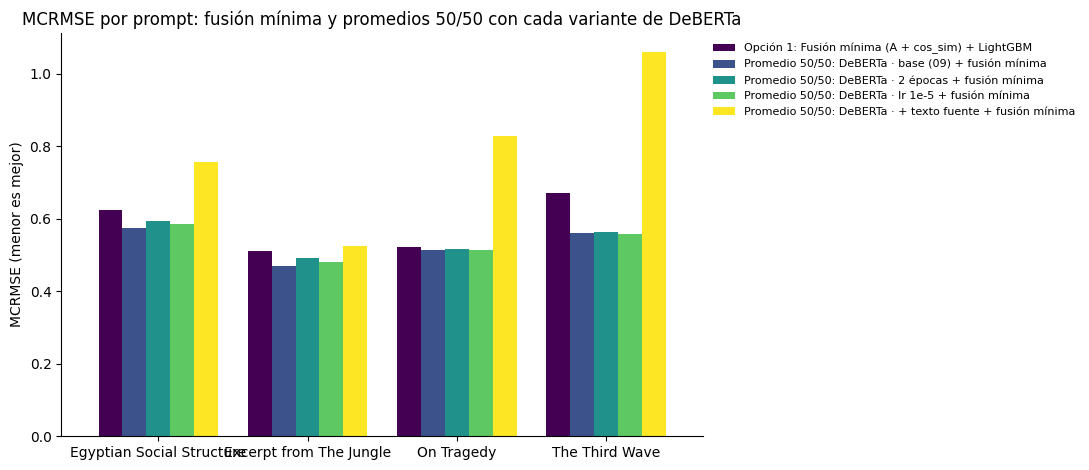

In [11]:
blend_by_prompt = (by_prompt[by_prompt["modelo"].isin(blend_names + [BLEND_BASE])]
                   .pivot(index="prompt_title", columns="modelo", values="mcrmse")[[BLEND_BASE, *blend_names]])
ax = blend_by_prompt.plot.bar(figsize=[11, 4.8], width=0.8, colormap="viridis")
ax.set(title="MCRMSE por prompt: fusión mínima y promedios 50/50 con cada variante de DeBERTa",
       xlabel="", ylabel="MCRMSE (menor es mejor)")
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(OUT_FIGURES / "10_deberta_tuning_by_prompt.png", dpi=150, bbox_inches="tight")
plt.show()

oof_rows = []
for variant, frame in predictions.items():
    oof = common[["student_id", "prompt_id", *TARGETS]].copy()
    oof["modelo"] = VARIANTS[variant]["label"]
    oof[PRED_COLUMNS] = aligned(frame)
    for target in TARGETS:
        oof[f"error_abs_{target}"] = (oof[target] - oof[f"pred_{target}"]).abs()
    oof_rows.append(oof)
columns_08 = ["student_id", "prompt_id", *TARGETS, "modelo", "pred_content", "error_abs_content",
              "pred_wording", "error_abs_wording"]
pd.concat(oof_rows, ignore_index=True)[columns_08].to_csv(RUN_DIR / "10_deberta_oof_predictions.csv", index=False)

* `10_deberta_oof_predictions.csv` tiene **las mismas columnas** que `08_oof_predictions.csv`, con una variante de
  DeBERTa por valor de `modelo`. Así la comparación final puede juntarlos directamente.

## 7. Conclusiones

Corrida completa en Colab (GPU T4), con las variantes y la configuración de la sección 1 sin cambios.

| Modelo (prompt no visto) | RMSE content | RMSE wording | MCRMSE | Promedio 50/50 con la fusión |
|---|---|---|---|---|
| DeBERTa · base (09) | **0.462** | **0.740** | **0.601** | **0.529** |
| DeBERTa · lr 1e-5 | 0.471 | 0.754 | 0.612 | 0.535 |
| DeBERTa · 2 épocas | 0.471 | 0.771 | 0.621 | 0.542 |
| DeBERTa · + texto fuente | 1.258 | 1.406 | 1.332 | 0.782 |
| Fusión mínima + LightGBM (08) | 0.480 | 0.671 | 0.576 | — |

1. **Ninguna variante mejora a la base del 09**, ni sola ni en el promedio. La selección honesta de la sección 6
   elige la base en los 4 prompts, así que la estimación honesta coincide con la base: 0.601 sola y 0.529 en el
   promedio.
2. **El problema no era el sobreajuste.** Con 2 épocas o con una tasa de aprendizaje más baja, el MSE de
   entrenamiento sube (0.20–0.22 y 0.17–0.19, contra 0.15–0.17 en 09) y el de validación **también** sube. Entrenar
   menos empeora el modelo. La brecha entre entrenamiento y validación viene del cambio de prompt, no de memorizar
   los datos de entrenamiento. La única excepción es *The Third Wave*, donde 2 épocas mejora (0.586 contra 0.627).
3. **El texto fuente rompe el modelo con prompts nuevos.** Entrena bien (MSE de entrenamiento 0.17–0.19, como la
   base), pero en validación queda peor que la media en 3 de los 4 prompts (MCRMSE 2.11 en *The Third Wave*, 1.45 en
   *On Tragedy* y 1.13 en *Egyptian Social Structure*; el Dummy da 1.05). Un error tan grande con buen entrenamiento
   se explica por un **desplazamiento sistemático**, y las predicciones out-of-fold lo confirman: el modelo
   **sobreestima** las dos puntuaciones en todos los prompts, en promedio entre +0.35 y +1.92 en `content` y entre
   +0.53 y +1.90 en `wording` (el peor caso es *The Third Wave*). Explicación probable, no comprobada aquí: con solo 3
   prompts de entrenamiento, el texto fuente funciona como una "etiqueta" del prompt. El modelo aprende atajos
   propios de esos 3 textos (por ejemplo, el nivel promedio de cada prompt) en vez de comparar el resumen con la
   fuente, y con un texto fuente nuevo esos atajos fallan. La hipótesis del 09 (que a DeBERTa le faltaba el texto
   fuente para `wording`) no se confirma con este diseño. Para aprender a comparar resumen y fuente harían falta
   muchos más prompts.
4. **Costo:** unos 22 min (2 épocas), 33 min (lr 1e-5) y 80 min (texto fuente) en una T4.

**En síntesis:** el ajuste de DeBERTa no mejoró a la configuración original. Reducir el entrenamiento empeora, y
agregar el texto fuente provoca un fallo de generalización con prompts no vistos, un ejemplo claro de por qué la
validación por prompt es necesaria. Los hiperparámetros iniciales ya estaban cerca de su mejor valor, y el modelo final sigue siendo el promedio
50/50 de DeBERTa base y la fusión mínima (MCRMSE 0.529).

## Cierre

Si el transformer ya estaba en su mejor configuración posible con estos datos, queda por ver si su compañero en el
promedio, la fusión mínima con LightGBM, todavía tiene margen. Sus hiperparámetros también se fijaron de antemano y,
a diferencia de DeBERTa, entrenarlo cuesta segundos, así que sí permite una búsqueda sistemática.